# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** maya

**Date:** [To be provided]

In [2]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd
df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:
#df.info()
df.isna().sum()
#df['age'] = df['age'].astype(int)
zero_count = (df['age'] == 0).sum()
print(zero_count)
count = ((df['smoking'] != 0) & (df['smoking'] != 1)).sum()
print(count)


0
0


In [4]:
print("Q2")
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier 
from sklearn.linear_model import LinearRegression

X = df.drop(columns="DEATH_EVENT")
y = df["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

tree = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
lm = LinearRegression().fit(X_train, y_train)

tree_pred = tree.predict_proba(X_test)[:, 1]
lm_pred = lm.predict(X_test)

print("tree accuracy:", tree.score(X_test, y_test))
print("linear accuracy:", ((lm_pred > 0.5) == y_test).mean())


Q2
tree accuracy: 0.8266666666666667
linear accuracy: 0.8666666666666667


In [5]:
print("Q3")
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier 
from sklearn.linear_model import LinearRegression

X = df.drop(columns="DEATH_EVENT")
y = df["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=2)

tree = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
lm = LinearRegression().fit(X_train, y_train)

tree_pred = tree.predict_proba(X_test)[:, 1]
lm_pred = lm.predict(X_test)

print("tree accuracy:", tree.score(X_test, y_test))
print("linear accuracy:", ((lm_pred > 0.5) == y_test).mean())

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier 
from sklearn.linear_model import LinearRegression

X = df.drop(columns="DEATH_EVENT")
y = df["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=43)

tree = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
lm = LinearRegression().fit(X_train, y_train)

tree_pred = tree.predict_proba(X_test)[:, 1]
lm_pred = lm.predict(X_test)

print("tree accuracy:", tree.score(X_test, y_test))
print("linear accuracy:", ((lm_pred > 0.5) == y_test).mean())

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier 
from sklearn.linear_model import LinearRegression

X = df.drop(columns="DEATH_EVENT")
y = df["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=100)

tree = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
lm = LinearRegression().fit(X_train, y_train)

tree_pred = tree.predict_proba(X_test)[:, 1]
lm_pred = lm.predict(X_test)

print("tree accuracy:", tree.score(X_test, y_test))
print("linear accuracy:", ((lm_pred > 0.5) == y_test).mean())
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier 
from sklearn.linear_model import LinearRegression

X = df.drop(columns="DEATH_EVENT")
y = df["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=150)

tree = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
lm = LinearRegression().fit(X_train, y_train)

tree_pred = tree.predict_proba(X_test)[:, 1]
lm_pred = lm.predict(X_test)

print("tree accuracy:", tree.score(X_test, y_test))
print("linear accuracy:", ((lm_pred > 0.5) == y_test).mean())



Q3
tree accuracy: 0.88
linear accuracy: 0.8533333333333334
tree accuracy: 0.8
linear accuracy: 0.8266666666666667
tree accuracy: 0.8133333333333334
linear accuracy: 0.8133333333333334
tree accuracy: 0.8
linear accuracy: 0.8266666666666667


Q4 pt. a


NameError: name 'seeds' is not defined

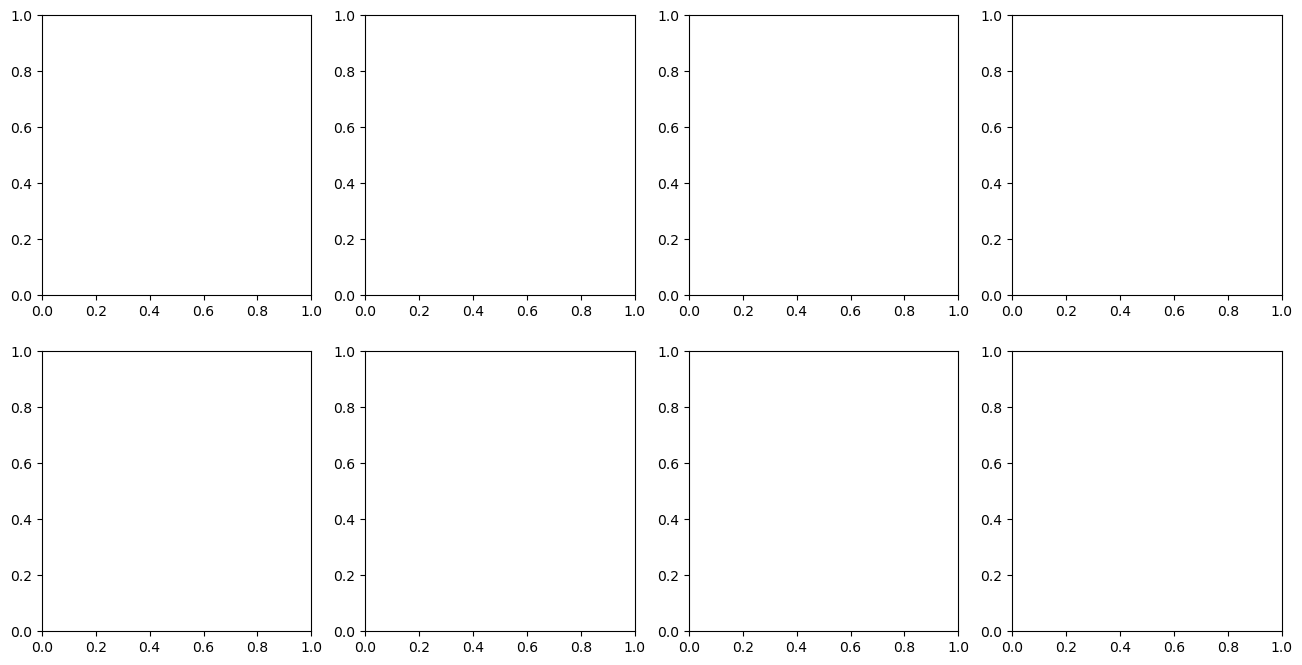

In [2]:
print ("Q4 pt. a")
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for row, model in enumerate(["Tree", "Linear"]):
    for col, seed in enumerate(seeds):
        x = baseline[model]
        y_alt = alternatives[seed][model]

        ax = axes[row, col]
        ax.scatter(x, y_alt, alpha=0.5)

        low = min(x.min(), y_alt.min())
        high = max(x.max(), y_alt.max())
        ax.plot([low, high], [low, high], "k--")
        ax.set_aspect("equal", adjustable="box")

        ax.set_title(f"{model}, seed {seed}")
        ax.set_xlabel("Q2 predictions")
        ax.set_ylabel("Alternative predictions")

plt.tight_layout()
plt.show()

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]